# Constructing the radial profiles for empirical PSFs. 
## This notebook displays an example for NIRCam filter F277W, it can also apply to other filters too. 

In [ ]:
# Import necessary libraries
import os
import sys
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

from astropy.visualization import simple_norm
from astropy.io import fits
from astropy.table import Table
from astropy.nddata import NDData

from photutils.detection import find_peaks
from photutils.psf import extract_stars
from photutils.psf import EPSFBuilder
from photutils.centroids import centroid_quadratic
from photutils.profiles import CurveOfGrowth
from photutils.background import Background2D, MedianBackground

In [ ]:
# Input filter names and PSF fits files 
fil_names = ['JWST_F090W', 'JWST_F115W', 'JWST_F150W', 'JWST_F200W', 'JWST_F277W', 'JWST_F356W', 'JWST_F410M', 'JWST_F444W'] #For PSF file format 
filters = ['jwst_nircam_f090w', 'jwst_nircam_f115w', 'jwst_nircam_f150w', 'jwst_nircam_f200w', 
            'jwst_nircam_f277w', 'jwst_nircam_f356w', 'jwst_nircam_f410m', 'jwst_nircam_f444w'] #Id for the dictionary 

# Directory of the PSFs
dir_images = '/Users/quocanh1306/Downloads/' #Replace with your own dir 

# Input empirical PSFs 
epsf = {}
epsf['jwst_nircam_f090w'] = 'PSF_%s.fits' % fil_names[0]
epsf['jwst_nircam_f115w'] = 'PSF_%s.fits' % fil_names[1]
epsf['jwst_nircam_f150w'] = 'PSF_%s.fits' % fil_names[2]
epsf['jwst_nircam_f200w'] = 'PSF_%s.fits' % fil_names[3]
epsf['jwst_nircam_f277w'] = 'PSF_%s.fits' % fil_names[4]
epsf['jwst_nircam_f356w'] = 'PSF_%s.fits' % fil_names[5]
epsf['jwst_nircam_f410m'] = 'PSF_%s.fits' % fil_names[6]
epsf['jwst_nircam_f444w'] = 'PSF_%s.fits' % fil_names[7]

In [ ]:
# check the headers 
hdu = fits.open('/Users/quocanh1306/Downloads/'+'ceers-full-grizli-v7.4-f090w-clear_drc_sci.fits.gz')
header = []
header.append(hdu[0].header)
print(repr(header[0]))

In [ ]:
# Import piXedfit to calculate the pixsize 
# Note: if pixsize is known, this part is not necessary 
os.environ["SPS_HOME"] = "/Users/quocanh1306/Desktop/Research/highredshiftgalaxies/fsps"
os.environ["PIXEDFIT_HOME"] = "/Users/quocanh1306/Desktop/Research/highredshiftgalaxies/piXedfit"
print("PIXEDFIT_HOME set to:", os.environ["PIXEDFIT_HOME"])

# Get pixel sizes of the images
from piXedfit.piXedfit_images.images_utils import calc_pixsize

## F277W

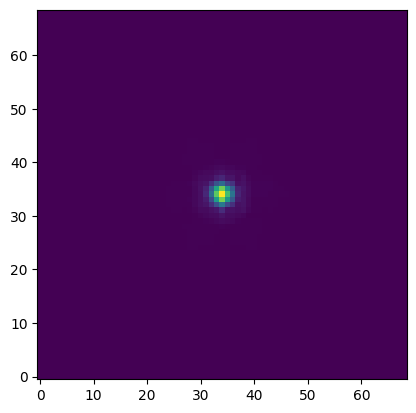

In [ ]:
# Import the empirical PSF file (linear scale)
hdu = fits.open(dir_images+epsf['jwst_nircam_f277w'])
plt.imshow(hdu[0].data, origin='lower')
plt.show()

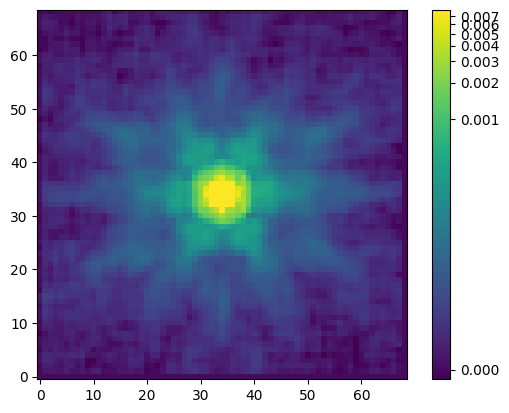

In [ ]:
# Display the EPSF image in log scale 
norm = simple_norm(hdu[0].data, 'log', percent=99.)
plt.imshow(hdu[0].data, norm=norm, origin='lower', cmap='viridis')
plt.colorbar()
plt.show()

In [ ]:
# Extract the centroid 
xycen = centroid_quadratic(hdu[0].data, xpeak=34, ypeak=35)
print(xycen)

[34.00925682 33.85594029]


In [ ]:
# Construct an error map 
bkg_estimator = MedianBackground()
bkg = Background2D(hdu[0].data, (15, 15), filter_size=(3, 3), bkg_estimator=bkg_estimator)

# The background RMS is your constant error estimate in 10*nJy
constant_error_value = bkg.background_rms

# Create a constant error array for photutils (less accurate than an ERR map)
error_map = np.full(hdu[0].data.shape, constant_error_value)

In [ ]:
# Extract the Curve of Growth 
radii =  np.arange(0.01, 50, 0.05)
cog = CurveOfGrowth(hdu[0].data, xycen, radii, error=error_map, mask=None)
cog.normalize(method='max')

# Calculate the Encircled Energy (EE) at each radius 
ee_vals = cog.calc_ee_at_radius(radii)

# Your plate scale (can be imported directly or calculated using the calc_pixsize function of piXedfit)
#PLATE_SCALE = 0.031 # arcsec/pixel
PLATE_SCALE = calc_pixsize(dir_cat+epsf[filters[4]])

# Get the radii of the *centers* of the annuli in pixels
radii_in_pixels = cog.radius

# Apply the conversion
cog.radius = radii_in_pixels * PLATE_SCALE

In [ ]:
# Create the DataFrame
data = {
    'Radius (arcsec)': cog.radius,
    'Normalized Flux (EE)': ee_vals
}
ee_df = pd.DataFrame(data)
print(ee_df)
file_path_df = '/Users/quocanh1306/Downloads/ee_west_df_f277w.csv' #Define your own path 
# Save as CSV to the specified path
ee_df.to_csv(file_path_df)

target_radius = 0.35
ee_targets = [0.50, 0.80, 0.95]

# Extract the data arrays from your DataFrame
radii = ee_df['Radius (arcsec)'].values  # The X-values
ee_flux = ee_df['Normalized Flux (EE)'].values # The Y-values

# Perform linear interpolation: np.interp(x_target, x_known, y_known)
ee_at_r_target = np.interp(target_radius, radii, ee_flux)
r_at_ee_target = np.round(np.interp(ee_targets, ee_flux, radii),4)

print(f"The Encircled Energy (EE) at a radius of {target_radius} arcsec is: {ee_at_r_target:.4f}")
print(f"The Aperture Correction at a radius of {target_radius} arcsec is: {(1/ee_at_r_target):.4f}")
print(f"The radius in arcsec at EE equals to 50%, 80%, 95% are: {r_at_ee_target}")

     Radius (arcsec)  Normalized Flux (EE)
0             0.0004              0.000019
1             0.0024              0.000691
2             0.0044              0.002324
3             0.0064              0.004916
4             0.0084              0.008469
..               ...                   ...
995           1.9904              1.000000
996           1.9924              1.000000
997           1.9944              1.000000
998           1.9964              1.000000
999           1.9984              1.000000

[1000 rows x 2 columns]
The Encircled Energy (EE) at a radius of 0.35 arcsec is: 0.8730
The Aperture Correction at a radius of 0.35 arcsec is: 1.1455
The radius in arcsec at EE equals to 50%, 80%, 95% are: [0.0886 0.2069 0.7148]


(-0.05, 1.8)

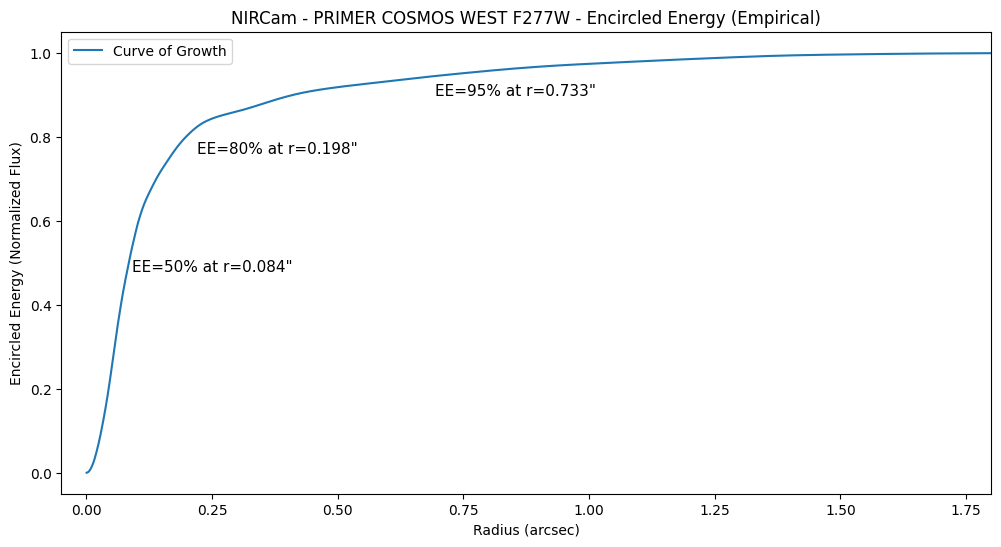

In [ ]:
# Plot the Radial Profile for our EPSF

fig, ax = plt.subplots(figsize=(12, 6))

# Annotation for EE=50%
plt.annotate(
    f'EE=50% at r={r_at_ee_target[0]:.3f}"',
    xy=(r_at_ee_target[0], 0.50),                     # Point on the curve (x, y)
    xytext=(0.091, 0.48),                  # Position for the text (x, y)
    fontsize=11,
    ha='left'
)

# Annotation for EE=80%
plt.annotate(
    f'EE=80% at r={r_at_ee_target[1]:.3f}"',
    xy=(r_at_ee_target[1], 0.80),
    xytext=(0.219, 0.76),
    fontsize=11,
    ha='left'
)

# Annotation for EE=95%
plt.annotate(
    f'EE=95% at r={r_at_ee_target[2]:.3f}"',
    xy=(r_at_ee_target[2], 0.95),
    xytext=(0.693, 0.90),
    fontsize=11,
    ha='left'
)

# Plot the Encircled Energy curve
cog.plot(ax=ax, label='Curve of Growth')
cog.plot_error(ax=ax)
ax.legend()

# Set labels and title to match standard practice
plt.xlabel('Radius (arcsec)')
plt.ylabel('Encircled Energy (Normalized Flux)')
plt.title('NIRCam - PRIMER COSMOS WEST F277W - Encircled Energy (Empirical)')
plt.xlim([-0.05,1.8])